## Setting up TypeSense Vector Store

In [1]:
import os
from langchain_community.document_loaders import PyPDFLoader, PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pathlib import Path

C:\Users\somya\AppData\Local\Temp\ipykernel_14588\3933654057.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader, PyMuPDFLoader
d:\Machine Learing Learn\LangChain and langGraph\RAG\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import numpy as np
from sentence_transformers import SentenceTransformer
from typing import List, Dict, Any, Tuple

In [3]:
def process_pdfs(pdf_directory):
    all_docs = [] #list to store all the pdf documents
    pdf_dir = Path(pdf_directory) #path of the pdf directory

    pdf_files = list(pdf_dir.glob("**/*.pdf")) #list containing all the pdf files extracted frm pdf directory using glob
    print(f"found {len(pdf_files)} pdf files..")

    for pdf_file in pdf_files:
        try:
            print(f"\nProcessing: {pdf_file.name}")
            loader = PyMuPDFLoader(str(pdf_file)) #loader obj to load a single pdf in a document data stucture
            docs = loader.load() #Content of a single pdf in document data structure

            #adding few metadata
            for doc in docs:
                doc.metadata['source_file'] = pdf_file.name 
                doc.metadata['file_type'] = 'pdf'

            #adding the all the document data structure of each pdf to the all_docs list
            all_docs.extend(docs)
            print(f"  ✓ Loaded {len(docs)} pages")

        except Exception as e:
            print(f"  ✗ Error: {e}")

    print(f"\nTotal documents loaded: {len(all_docs)}")
    return all_docs


In [4]:
all_pdf_documents = process_pdfs("../data")

found 7 pdf files..

Processing: L1.pdf
  ✓ Loaded 26 pages

Processing: L2.pdf
  ✓ Loaded 27 pages

Processing: L3.pdf
  ✓ Loaded 24 pages

Processing: L4.pdf
  ✓ Loaded 29 pages

Processing: L5.pdf
  ✓ Loaded 27 pages

Processing: L6.pdf
  ✓ Loaded 29 pages

Processing: L7.pdf
  ✓ Loaded 28 pages

Total documents loaded: 190


In [5]:
def split_documents(documents,chunk_size=1000,chunk_overlap=200):
    """Split documents into smaller chunks for better RAG performance"""

    #RecursiveCharacterTextSplitter obj that is going to chunk the documents in all_docs
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        length_function=len,
        separators=["\n\n", "\n", " ", ""]
    )
    split_docs = text_splitter.split_documents(documents)
    print(f"Split {len(documents)} documents into {len(split_docs)} chunks")
    
    
    if split_docs:
        print(f"\nExample chunk:")
        print(f"Content: {split_docs[0].page_content[:200]}...")
        print(f"Metadata: {split_docs[0].metadata}")
    
    return split_docs

In [6]:
chunks=split_documents(all_pdf_documents)
chunks

Split 190 documents into 701 chunks

Example chunk:
Content: ​Introduction​
​Cool. Hello everyone, and welcome to CME 295-- Transformers and Large Language​
​Models. So my name is Afshine. And I will be teaching this class with Shervine, who's​
​in the back. An...
Metadata: {'producer': 'Skia/PDF m154', 'creator': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/154.0.0.0 Safari/537.36', 'creationdate': '2026-10-09T10:25:21+00:00', 'source': '..\\data\\pdf\\L1.pdf', 'file_path': '..\\data\\pdf\\L1.pdf', 'total_pages': 26, 'format': 'PDF 1.4', 'title': 'CME 295 TRANSCRIPT - Google Docs', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2026-10-09T10:25:21+00:00', 'trapped': '', 'modDate': "D:20261009102521+00'00'", 'creationDate': "D:20261009102521+00'00'", 'page': 0, 'source_file': 'L1.pdf', 'file_type': 'pdf'}


[Document(metadata={'producer': 'Skia/PDF m154', 'creator': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/154.0.0.0 Safari/537.36', 'creationdate': '2026-10-09T10:25:21+00:00', 'source': '..\\data\\pdf\\L1.pdf', 'file_path': '..\\data\\pdf\\L1.pdf', 'total_pages': 26, 'format': 'PDF 1.4', 'title': 'CME 295 TRANSCRIPT - Google Docs', 'author': '', 'subject': '', 'keywords': '', 'moddate': '2026-10-09T10:25:21+00:00', 'trapped': '', 'modDate': "D:20261009102521+00'00'", 'creationDate': "D:20261009102521+00'00'", 'page': 0, 'source_file': 'L1.pdf', 'file_type': 'pdf'}, page_content="\u200bIntroduction\u200b\n\u200bCool. Hello everyone, and welcome to CME 295-- Transformers and Large Language\u200b\n\u200bModels. So my name is Afshine. And I will be teaching this class with Shervine, who's\u200b\n\u200bin the back. And before I start, I'm just going to introduce ourselves. So we're twin\u200b\n\u200bbrothers, and we actually had a similar backgrou

In [7]:
from langchain_community.vectorstores import Typesense
from langchain_huggingface import HuggingFaceEmbeddings

embedding_model = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")

docsearch = Typesense.from_documents(
    documents=chunks,
    embedding=embedding_model,
    typesense_client_params={
        "host": "70mcbqkhtixy54a6p-1.a2.typesense.net",
        "port": "443",
        "protocol": "https",
        "typesense_api_key": "fDHAQS3pZBC5uFKQj6nmL5k70soMZ158",
        "typesense_collection_name": "RAG"
    }
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2941.25it/s]


In [8]:
query = "What is an LLM"
found_docs = docsearch.similarity_search(query)
print(found_docs[0].page_content)

​and normalization. So we only keep this. And this is the backbone of LLMs. And so I​
​mentioned GPT is kind of a good example. But it's not just that. You have plenty of​
​other models. So you may have heard of LLaMA from Meta, Gemma from Google,​
​DeepSeek, Mistral, Qwen, and so on. The list is long. I would say roughly-- I mean,​
​more than 90% of modern day LLMs, they're all decoder-only. So I think that's​
​something to keep in mind. Cool. OK. So now you how LLMs are made of.​


In [9]:
retriever = docsearch.as_retriever()
retriever

VectorStoreRetriever(tags=['Typesense', 'HuggingFaceEmbeddings'], vectorstore=<langchain_community.vectorstores.typesense.Typesense object at 0x000001EEAE9D2270>, search_kwargs={})

In [10]:
query = "why masked multi head attention?"
retriever.invoke(query)[0]

Document(metadata={'author': '', 'creationDate': "D:20261009102521+00'00'", 'creationdate': '2026-10-09T10:25:21+00:00', 'creator': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/154.0.0.0 Safari/537.36', 'file_path': '..\\data\\pdf\\L1.pdf', 'file_type': 'pdf', 'format': 'PDF 1.4', 'keywords': '', 'modDate': "D:20261009102521+00'00'", 'moddate': '2026-10-09T10:25:21+00:00', 'page': 21, 'producer': 'Skia/PDF m154', 'source': '..\\data\\pdf\\L1.pdf', 'source_file': 'L1.pdf', 'subject': '', 'title': 'CME 295 TRANSCRIPT - Google Docs', 'total_pages': 26, 'trapped': ''}, page_content='\u200bright? Any questions on this? Yeah.\u200b\n\u200bAll right, that\'s a great question. The question is, what does head mean? So I guess I\u200b\n\u200bwent too fast. I ignored that part. But when you do the self-attention computation,\u200b\n\u200byou basically make queries interact with keys, and then take the corresponding value.\u200b\n\u200bBut nothing preven

## Agentic RAG

In [15]:
from langchain_core.tools import create_retriever_tool
from langchain_tavily import TavilySearch
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition

In [11]:
import os
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_groq import ChatGroq

load_dotenv()

llm1 = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0,
    google_api_key=os.getenv("GOOGLE_API_KEY")
)

llm2 = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    groq_api_key=os.getenv("GROQ_API_KEY")
)


In [12]:
# res = llm1.invoke("hi")
# print("LLM Initialized:", res.content)

# res = llm2.invoke("hi")
# print("LLM Initialized:", res.content)

In [16]:
retriever_tool = create_retriever_tool(
    retriever,
    name="lecture_notes_search",
    description=(
        "Search the CME 295 Transformers and LLM lecture transcripts. "
        "Use this for questions about transformers, attention, LLMs, "
        "training, fine-tuning, and other course topics."
    ),
)

In [17]:
web_search_tool = TavilySearch(
    max_results=3,
    description="Search the internet for recent news, current events, or topics not covered in the Transcripts."
)

In [18]:
tools = [retriever_tool, web_search_tool]

llm_with_tools = llm1.bind_tools(tools)

In [19]:
system_prompt = SystemMessage(content=(
    "You are a helpful assistant. "
    "For questions about transformers or LLM course topics, first use the lecture_notes_search tool. "
    "For recent news or things not in the lecture notes, use the web search tool. "
    "If the question is simple, answer directly without tools. "
    "Mention whether your answer came from the lecture notes or the web."
))

def agent(state: MessagesState):
    messages = [system_prompt] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

In [20]:
builder = StateGraph(MessagesState)

# add nodes
builder.add_node("agent", agent)
builder.add_node("tools", ToolNode(tools))

# add edges
builder.add_edge(START, "agent")
builder.add_conditional_edges("agent", tools_condition)
builder.add_edge("tools", "agent")

graph = builder.compile()

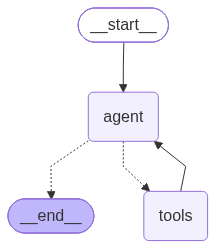

In [21]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [22]:
def ask(question):
    result = graph.invoke({"messages": [HumanMessage(content=question)]})
    for msg in result["messages"]:
        msg.pretty_print()

In [23]:
ask("What are the latest AI model releases this week?")

================================ Human Message =================================

What are the latest AI model releases this week?
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_1776655)
 Call ID: call_1776655
  Args:
    time_range: week
    query: latest AI model releases this week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI model releases this week", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.cnet.com/tech/services-and-software/anthropic-google-and-mistral-unveil-their-latest-ai-models-for-claude-sonnet-haiku-and-gemini", "title": "Anthropic, Google and Mistral Unveil Their Latest AI Models: What’s New and Why It Matters - CNET", "content": "The AI race hasn’t slowed down. In the last week, Google, Anthropic and Mistral AI all released new AI models ranging from widely a

In [24]:
ask("What is 15 multiplied by 4?")

================================ Human Message =================================

What is 15 multiplied by 4?
================================== Ai Message ==================================

[{'type': 'text', 'text': '15 multiplied by 4 is **60**. \n\n*(This answer was calculated directly without using the lecture notes or web search.)*', 'extras': {'signature': 'ErkFCrYFAWkUfROBxlv46iKanAYu19En10yQamGp55fYw0ObPDio9PobVmdEts6meISqZIVLvIf4CaQprZal8ZN1sGFhkv6U6Os7uJOFKA+605PUn7d6m1gjkBT6I73HasXuuSDYcJjHB+OhOr/NTTi7Ur9PWoeUGRpgWyuxpB85V1sZLG0NjmoRg+LFZbmqD9rNrIjdC4MUYLIacPwLsiMfrnFq+ViWC4AF7F4XwTiN2MqBN6qjHoB0Ofgg5JCC/qm6sL36EK8znONolTRgpiXhDdGZNSgv5UuPtgGDHiaKn8YNsKJJqyMiwAEBAgm0fOQvxEH3n8Ngd1EAGWl7Agc3Zn3QLJfSIQmyHmSs/ewWYsrcrzJ28PlVg1f6cudafP2lgrRpt2RO9WSbXrOjtfKFiLXOfh4zDrWGUD6mrukaKIBDZFBOYfkto/dZa+GJS2MJKDP55zKJaRi2rNbQJooWFCawx1CnhyJz80mY9XiQkFT1t80aRL1Hmu/KhxcV7Je9ylXdqK2VJWc3/z1XcEOuM0lTwL2B8lwo/AxreQhL3yn3HGgxQb+IJpKagSNUUSaZYYjm1qan3702VhS/Hv8mCLBDGG6+6BAKopVv38GJ6ixP3RjCzX8NV

In [25]:
ask("What is an LLM?")

================================ Human Message =================================

What is an LLM?
================================== Ai Message ==================================

[]
Tool Calls:
  lecture_notes_search (call_792996)
 Call ID: call_792996
  Args:
    query: What is an LLM large language model
================================= Tool Message =================================
Name: lecture_notes_search

​LLM definition​
​Cool. So with that, I'm going to introduce the term LLM. So LLM stands for large​
​language model. So what is a large language model? So first of all, a large language​
​model is a language model. So a language model is a model that assigns probability to​
​sequences of tokens. So in this case, our model always predicts the probability of the​
​next token. So it's, in that sense, a language model. But also, a large language model is​
​large. So why is it large? So we're going to see that these models, they are actually​
​scaled up in terms of size. So first 